# Chile: CMF B-1, IFRS 9 y el Anexo 9 del Banco de España sobre una misma cartera (Banco Andino)

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir por qué los bancos chilenos no contabilizan el deterioro de IFRS 9 sobre los préstamos, y de dónde vienen las provisiones B-1 de la CMF;
- leer el método estándar B-1, el factor $PE = PI \times PDI$ por grupo, la regla del máximo entre el método estándar y uno interno, el mínimo de 0,50 % y las provisiones adicionales, y calcular cada uno con el motor sobre cuentas construidas;
- leer las tablas de cobertura del Anejo 9 del Banco de España y la correspondencia de sus categorías con las etapas de IFRS 9;
- provisionar un banco sintético bajo los tres regímenes, y leer la brecha entre B-1 e IFRS 9 como un puente de decisiones de medición;
- decir qué pasa con la brecha entre los regímenes cuando la economía se tensiona de cinco maneras distintas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C07, **Banco Andino**, un banco **sintético** generado y calibrado a agregados públicos de la CMF, la Comisión para el Mercado Financiero de Chile. No es un banco real ni evidencia sobre ningún banco; el aviso versionado lo dice, y el cuaderno lo imprime. Su cartera tiene seis segmentos (hipotecarios por razón préstamo a garantía, consumo en cuotas, tarjetas, y comerciales de evaluación grupal o individual) y unas 171.000 cuentas, en pesos chilenos (CLP). La misma cartera se provisiona bajo tres regímenes y seis escenarios, un archivo cada uno.

- **Archivos que se leen:** `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` y `combined-severe.json`, y `data/derived/C07/models-banco-andino.json` para las ranuras de modelo. En cada archivo de escenario: `outputs.comparison` (las tres provisiones por segmento), `outputs.gap_bridge`, `outputs.b1_detail`, `outputs.ifrs9_detail`, `outputs.bde_detail` y, desde el segundo escenario, `outputs.delta_vs_base`.
- **Los regímenes:** CMF B-1 es la provisión estatutaria que los bancos chilenos contabilizan sobre los préstamos; la columna IFRS 9 es una **medida de comparación** y no lo que contabilizan los bancos chilenos (el capítulo A-2 N 5 del CNCB deja los préstamos a B-1); el Anejo 9 del Banco de España es la solución alternativa del PCGA español.
- **Supuestos del caso:** los choques de los escenarios, los ajustes y las provisiones adicionales son supuestos del caso, no trayectorias ni datos chilenos.

La celda siguiente carga los seis escenarios y el archivo de modelos e imprime el aviso versionado, las ranuras de modelo y las versiones del motor.

In [2]:
# Cargar los seis escenarios de Banco Andino y el archivo de modelos, e imprimir el aviso y las ranuras de modelo
from riskvalidation.provisions import local_cl as cl, local_es as es

LANG = "es"
ROOT = Path("../../..").resolve()
NAMES = ["base", "recession", "house-price-fall", "consumer-arrears-shock", "uf-inflation-spike", "combined-severe"]


def read(name):
    return json.loads((ROOT / "data" / "derived" / "C07" / f"{name}.json").read_text(encoding="utf-8"))


scenarios = {name: read(name) for name in NAMES}
models = read("models-banco-andino")
base = scenarios["base"]["outputs"]
print(base["notice"][LANG])
print("sintético:", si_no(base["synthetic"]), "|", si_no(scenarios["base"]["provenance"]["truth_status"]), "| moneda:", base["currency"])
print("ranuras de modelo:", [(m["id"], m["engine"]) for m in models["model"]])
print("calculado por el motor:", {n: s["provenance"]["riskvalidation_version"] for n, s in scenarios.items()}, "| motor instalado:", md.version("riskvalidation"))
print("cuentas:", sum(seg["accounts"] for seg in base["portfolio"]["segments"]), "| exposición bruta, miles de millones de CLP:", round(sum(seg["gross_exposure"] for seg in base["portfolio"]["segments"]) / 1e9, 1))

Datos sintéticos: Banco Andino es un banco generado, calibrado a agregados públicos del sistema de la CMF; no es un banco real ni evidencia sobre ningún banco. CMF B-1 es la provisión estatutaria que los bancos chilenos constituyen sobre colocaciones; la columna IFRS 9 es una medida de comparación, no la provisión que los bancos chilenos constituyen sobre colocaciones (CNCB A-2 N 5 deja las colocaciones a B-1); el Anejo 9 del BdE es la solución alternativa del PGC español. Montos en CLP.
sintético: sí | sintética calibrada | moneda: CLP
ranuras de modelo: [('G0-banco-andino', 'none'), ('B1-standard', 'riskvalidation.provisions.local_cl'), ('IFRS9-ecl', 'riskvalidation.provisions.ecl'), ('BDE-annex9', 'riskvalidation.provisions.local_es')]
calculado por el motor: {'base': '0.5.0', 'recession': '0.5.0', 'house-price-fall': '0.5.0', 'consumer-arrears-shock': '0.5.0', 'uf-inflation-spike': '0.5.0', 'combined-severe': '0.5.0'} | motor instalado: 0.8.1
cuentas: 171500 | exposición bruta, mil

## Método

**Por qué tres regímenes.** Los bancos chilenos adoptaron IFRS 9 en el compendio contable de la CMF (CNCB) en 2022 **salvo** el capítulo de deterioro para préstamos: las provisiones sobre préstamos y créditos contingentes siguen bajo los capítulos B-1 a B-3 (CNCB A-2 N 5). La provisión B-1 es una fórmula supervisora, no una pérdida crediticia esperada. Los bancos españoles, bajo la Circular 4/2017 del Banco de España, sí aplican el modelo de IFRS 9, con «soluciones alternativas» supervisoras para la estimación colectiva. Contraste provisiona un banco sintético bajo los tres, para mostrar dónde coinciden y dónde no.

**CMF B-1, los métodos estándar** (CNCB B-1 N 3). Para una cartera grupal el factor de provisión es el producto de la probabilidad de incumplimiento y la pérdida dado el incumplimiento de la celda de una tabla, por grupo de exposición y días de mora:

$$PE = PI \times PDI, \qquad \mathrm{Prov}_{\mathrm{grupo}} = EG\,(1 - s)\,PE_{\mathrm{grupo}} + EG\,s\,PE_{\mathrm{avalista}}, \qquad \mathrm{Prov} = \max\bigl(\mathrm{Prov}^{\mathrm{estándar}}, \mathrm{Prov}^{\mathrm{interno}}\bigr)$$

con $EG$ la exposición del grupo y $s$ la fracción garantizada (B-1 N 4.1); la regla del máximo se aplica salvo que el método interno tenga la «no objeción» de la CMF (B-1 N 3). Un deudor evaluado individualmente tiene una categoría A1 a A6 (normal) o B1 a B4 (subestándar) con su propio $PE$ (N 2.1). La provisión mínima de 0,50 % se aplica solo a la cartera normal evaluada individualmente, y las provisiones adicionales (contracíclicas) son una línea separada, dentro de los límites de la política del directorio y nunca parte del total comparable (N 9).

**El Anejo 9 del Banco de España** (Circular 4/2017, modificada por la Circular 6/2021, tablas de los puntos 140, 144 y 172 desde el 30 de junio de 2022). La cobertura es un coeficiente del monto no cubierto por garantías eficaces, por segmento y categoría de riesgo:

$$\mathrm{Cobertura} = c_{s,k}\,\max\Bigl(0,\ \mathrm{EAD} - \sum_g \mathrm{ValorAjustado}_g\Bigr)$$

con el riesgo normal y normal en vigilancia especial por el punto 144, el riesgo dudoso por morosidad por el punto 140, y la correspondencia de categorías a etapas (normal a la Etapa 1, vigilancia especial a la Etapa 2, dudoso a la Etapa 3).

**IFRS 9 como medida de comparación** es la PCE ponderada por probabilidad de los cuadernos 01 a 03 con los ajustes como líneas separadas (cuaderno 04). Las funciones del motor calculan y no declaran cumplimiento; los números de punto del Anejo 9 son los de la Circular 6/2021 y si cambiaron después de la Circular 1/2025 no se verifica aquí.

### Paso 1: las tablas B-1, celda por celda

El motor guarda las tablas B-1 transcritas celda por celda, con el párrafo fuente en el código. Llamamos a las búsquedas sobre cuentas **construidas** para leer las tablas: un hipotecario de vivienda por razón préstamo a garantía (PVG, el capital insoluto sobre el valor de la garantía) y días de mora, un préstamo comercial con y sin garantía, y un préstamo de consumo. Cada una devuelve $(PI, PDI, PE)$. En las celdas hipotecarias el $PE$ transcrito es igual a $PI \times PDI$ dentro del redondeo propio de la tabla, lo que la celda verifica. La celda hipotecaria de 40 % a 80 % con cero días es la que cita la investigación: 0,0421 % como decimal, 0,000421.

In [3]:
# Leer las celdas B-1 hipotecaria, comercial y de consumo para cuentas construidas y verificar PE = PI x PDI
print("hipotecario: PVG, días de mora -> (PI, PDI, PE)")
for pvg in (0.35, 0.60, 0.85, 0.95):
    for dpd in ("0", "30-59", "default"):
        pi, pdi, pe = cl.b1_mortgage_pe(pvg, dpd)
        print(f"  PVG {pvg:.2f} | {dpd:8s} | PI {pi:.6f} | PDI {pdi:.6f} | PE {pe:.6f} | PI x PDI {pi * pdi:.6f}")
print("PE es igual a PI x PDI dentro de 5e-7 en las veinte celdas hipotecarias:", si_no(all(abs(cl.b1_mortgage_pe(v, d)[2] - cl.b1_mortgage_pe(v, d)[0] * cl.b1_mortgage_pe(v, d)[1]) <= 5e-7 for v in (0.3, 0.6, 0.85, 0.95) for d in ("0", "1-29", "30-59", "60-89", "default"))))
print("comercial, al día: con garantía con este PTVG, y sin ella:", 0.8, [round(v, 6) for v in cl.b1_commercial_pe("0", 0.8)], [round(v, 6) for v in cl.b1_commercial_pe("0", None)])
print("consumo en cuotas, 5 días de atraso, hipoteca en el sistema, sin mora:", [round(v, 6) for v in cl.b1_consumer_pe(5, True, False, "instalment")])
print("categorías individuales A1, A4, B4 (PI, PDI, PE):", [tuple(round(v, 6) for v in cl.b1_individual_category(c)) for c in ("A1", "A4", "B4")])
try:
    cl.b1_mortgage_pe(0.6, "45")
except ValueError as error:
    print("rechazado:", type(error).__name__)

hipotecario: PVG, días de mora -> (PI, PDI, PE)
  PVG 0.35 | 0        | PI 0.010916 | PDI 0.000225 | PE 0.000002 | PI x PDI 0.000002
  PVG 0.35 | 30-59    | PI 0.460536 | PDI 0.000482 | PE 0.000222 | PI x PDI 0.000222
  PVG 0.35 | default  | PI 1.000000 | PDI 0.000537 | PE 0.000537 | PI x PDI 0.000537
  PVG 0.60 | 0        | PI 0.019158 | PDI 0.021955 | PE 0.000421 | PI x PDI 0.000421
  PVG 0.60 | 30-59    | PI 0.520824 | PDI 0.029192 | PE 0.015204 | PI x PDI 0.015204
  PVG 0.60 | default  | PI 1.000000 | PDI 0.030413 | PE 0.030413 | PI x PDI 0.030413
  PVG 0.85 | 0        | PI 0.025150 | PDI 0.215527 | PE 0.005421 | PI x PDI 0.005421
  PVG 0.85 | 30-59    | PI 0.525800 | PDI 0.219200 | PE 0.115255 | PI x PDI 0.115255
  PVG 0.85 | default  | PI 1.000000 | PDI 0.222310 | PE 0.222310 | PI x PDI 0.222310
  PVG 0.95 | 0        | PI 0.027400 | PDI 0.272000 | PE 0.007453 | PI x PDI 0.007453
  PVG 0.95 | 30-59    | PI 0.530800 | PDI 0.295900 | PE 0.157064 | PI x PDI 0.157064
  PVG 0.95 | defa

### Paso 2: la provisión grupal, la regla del máximo, el mínimo y las provisiones adicionales

`b1_group_provision` calcula $EG(1-s)PE + EG\,s\,PE_{\mathrm{avalista}}$; `b1_group_max_rule` devuelve el monto aplicado y el método; `b1_minimum_normal_check` la prueba del 0,50 % de la cartera normal evaluada individualmente; `b1_additional_provisions` verifica un monto contra los límites del directorio. La celda las llama primero sobre números construidos, y luego **reproduce el detalle B-1 versionado de Banco Andino**: para cada segmento grupal la provisión estándar es la aplicada porque el banco no tiene método interno (la razón versionada está registrada solo en inglés), la prueba del mínimo se recalcula desde la exposición y la provisión versionadas, y las provisiones adicionales están dentro de su rango de política.

In [4]:
# La provisión grupal, la regla del máximo, el mínimo y las provisiones adicionales, sobre números construidos y luego sobre el detalle versionado de Banco Andino
print("provisión grupal para una exposición, el PE del grupo, la fracción garantizada y el PE del avalista:", (1000.0, 0.05, 0.20, 0.01), round(cl.b1_group_provision(1000.0, 0.05, 0.20, 0.01), 4))
print("regla del máximo: estándar 100, interno 120; no objetado; sin método interno:", cl.b1_group_max_rule(100.0, 120.0), cl.b1_group_max_rule(100.0, 120.0, True), cl.b1_group_max_rule(100.0, None))
print("provisión individual, exposición 1000, categoría A4:", cl.b1_individual_provision(1000.0, 0.0, "A4"))

detail = base["b1_detail"]
for row in detail["group_max_rule"]:
    applied, method = cl.b1_group_max_rule(row["standard"], row["internal"])
    print(f"{row['segment_id']:20s} aplicado, millones de CLP: {applied / 1e6:10.1f} | método: {method} | igual al versionado: {si_no(applied == row['applied'] and method == row['method'])}")
print("razón de las filas versionadas (la primera):", detail["group_max_rule"][0]["internal_reason"][LANG] if isinstance(detail["group_max_rule"][0]["internal_reason"], dict) else "en el registro versionado (solo en inglés)")

minimum = detail["minimum_check"]
check = cl.b1_minimum_normal_check(minimum["normal_portfolio_exposure"], minimum["normal_portfolio_provision_before_minimum"])
print("mínimo de la cartera normal: monto, vinculante, complemento:", round(check.minimum_amount / 1e6, 1), si_no(check.binding), check.top_up, "| monto versionado:", round(minimum["minimum_amount"] / 1e6, 1))
tight = cl.b1_minimum_normal_check(minimum["normal_portfolio_exposure"], 5e9)
print("con una provisión de 5 mil millones el mínimo es vinculante; vinculante, complemento en millones de CLP:", si_no(tight.binding), round(tight.top_up / 1e6, 1))
extra = detail["additional_provisions"]
print("provisiones adicionales, millones de CLP, dentro de la política [0, 15000]:", cl.b1_additional_provisions(extra["amount"], extra["policy_min"], extra["policy_max"]) / 1e6)
try:
    cl.b1_additional_provisions(20e9, extra["policy_min"], extra["policy_max"])
except ValueError as error:
    print("fuera de la política, rechazado:", type(error).__name__)
print("total B-1 contabilizado, total comparable y provisiones adicionales, millones de CLP:", round(detail["booked_total"] / 1e6, 1), round(scenarios["base"]["impact"]["provision_cmf_b1"]["value"] / 1e6, 1), round(extra["amount"] / 1e6, 1))

provisión grupal para una exposición, el PE del grupo, la fracción garantizada y el PE del avalista: (1000.0, 0.05, 0.2, 0.01) 42.0
regla del máximo: estándar 100, interno 120; no objetado; sin método interno: (120.0, 'max') (120.0, 'internal') (100.0, 'standard')
provisión individual, exposición 1000, categoría A4: 17.5
mortgage-ltv-le80    aplicado, millones de CLP:     1626.7 | método: standard | igual al versionado: sí
mortgage-ltv-gt80    aplicado, millones de CLP:    11229.1 | método: standard | igual al versionado: sí
consumer-instalment  aplicado, millones de CLP:    29229.0 | método: standard | igual al versionado: sí
consumer-cards       aplicado, millones de CLP:    26899.5 | método: standard | igual al versionado: sí
commercial-group     aplicado, millones de CLP:    24191.8 | método: standard | igual al versionado: sí
razón de las filas versionadas (la primera): en el registro versionado (solo en inglés)
mínimo de la cartera normal: monto, vinculante, complemento: 8457.4 n

### Paso 3: las tablas del Anejo 9 y la correspondencia de etapas

`annex9_normal_coverage` lee el punto 144 y `annex9_doubtful_coverage` el punto 140, por código de segmento (A.* para empresas, B.* para hogares) y por la antigüedad del importe vencido más antiguo en días; `annex9_coverage` aplica el coeficiente al monto no cubierto. La celda lee unas celdas para cuentas **construidas**, y luego verifica el detalle del Anejo 9 versionado de Banco Andino: la tasa de cobertura de cada categoría (provisión sobre exposición) y su etapa correspondiente contra la correspondencia del motor `annex9_category_to_stage`.

In [5]:
# Leer coeficientes del Anejo 9 sobre cuentas construidas y verificar las categorías versionadas y su correspondencia de etapas
print("punto 144, normal y vigilancia especial, B.1.1 vivienda:", es.annex9_normal_coverage("B.1.1", "normal"), es.annex9_normal_coverage("B.1.1", "normal-special-watch"))
print("punto 144, normal, B.2 consumo y A.1.1 construcción:", es.annex9_normal_coverage("B.2", "normal"), es.annex9_normal_coverage("A.1.1", "normal"))
print("punto 140, B.1.1 vivienda, por días de mora:", [(d, es.annex9_doubtful_coverage("B.1.1", d)) for d in (91, 183, 184, 365, 700)])
print("cobertura: EAD 1000, garantías ajustadas 300, B.1.1 normal:", es.annex9_coverage("B.1.1", "normal", 1000.0, [300.0]))
try:
    es.annex9_coverage("B.1.1", "doubtful", 1000.0, [])
except ValueError as error:
    print("una cuenta dudosa sin días de mora se rechaza:", type(error).__name__)

for row in base["bde_detail"]["categories"]:
    rate = row["provision"] / row["exposure"]
    print(f"{row['category']:22s} etapa correspondiente: {row['mapped_stage']} | la correspondencia del motor coincide: {si_no(es.annex9_category_to_stage(row['category']) == row['mapped_stage'])} | tasa de cobertura, versionada y recalculada: {row['coverage_rate']:.6f} {rate:.6f}")

punto 144, normal y vigilancia especial, B.1.1 vivienda: 0.007 0.18
punto 144, normal, B.2 consumo y A.1.1 construcción: 0.018 0.019
punto 140, B.1.1 vivienda, por días de mora: [(91, 0.45), (183, 0.45), (184, 0.5), (365, 0.65), (700, 1.0)]
cobertura: EAD 1000, garantías ajustadas 300, B.1.1 normal: 4.9
una cuenta dudosa sin días de mora se rechaza: ValueError
normal                 etapa correspondiente: stage1 | la correspondencia del motor coincide: sí | tasa de cobertura, versionada y recalculada: 0.003723 0.003723
normal-special-watch   etapa correspondiente: stage2 | la correspondencia del motor coincide: sí | tasa de cobertura, versionada y recalculada: 0.057243 0.057243
doubtful               etapa correspondiente: stage3 | la correspondencia del motor coincide: sí | tasa de cobertura, versionada y recalculada: 0.265210 0.265210


### Paso 4: una cartera, tres provisiones

Ahora los tres regímenes lado a lado en el escenario base. `outputs.comparison` da, para cada segmento, la provisión B-1, la PCE IFRS 9 y la cobertura del Anejo 9, y las líneas sin asignar (los ajustes IFRS 9). La celda recalcula los totales sumando los segmentos, los compara con los valores de `impact` versionados, imprime la cobertura por segmento y la razón de cada régimen a B-1. Las provisiones adicionales B-1 no están en el total comparable.

In [6]:
# Sumar los segmentos de cada régimen, comparar con los totales versionados e imprimir la cobertura por segmento
comparison = base["comparison"]
segments = {s["segment_id"]: s for s in base["portfolio"]["segments"]}
keys = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in keys}
committed = {"cmf_b1_provision": "provision_cmf_b1", "ifrs9_provision": "provision_ifrs9", "bde_annex9_provision": "provision_bde"}
for k in keys:
    print(f"{k:22s} suma de segmentos más sin asignar, millones de CLP: {totals[k] / 1e6:12.1f} | versionado: {scenarios['base']['impact'][committed[k]]['value'] / 1e6:12.1f}")
print("IFRS 9 sobre B-1, BdE sobre B-1:", round(totals["ifrs9_provision"] / totals["cmf_b1_provision"], 4), round(totals["bde_annex9_provision"] / totals["cmf_b1_provision"], 4))
print("cobertura por segmento: B-1, IFRS 9, Anejo 9")
for r in comparison["rows"]:
    exposure = segments[r["segment_id"]]["gross_exposure"]
    print(f"  {r['segment_id']:24s}", *[f"{r[k] / exposure:8.4f}" for k in keys])
print("líneas sin asignar (ajustes IFRS 9), millones de CLP:", round(comparison["unallocated"]["ifrs9_provision"] / 1e6, 1))

cmf_b1_provision       suma de segmentos más sin asignar, millones de CLP:     152000.6 | versionado:     152000.6
ifrs9_provision        suma de segmentos más sin asignar, millones de CLP:      97592.0 | versionado:      97592.0
bde_annex9_provision   suma de segmentos más sin asignar, millones de CLP:      79618.5 | versionado:      79618.5
IFRS 9 sobre B-1, BdE sobre B-1: 0.6421 0.5238
cobertura por segmento: B-1, IFRS 9, Anejo 9
  mortgage-ltv-le80          0.0011   0.0064   0.0000
  mortgage-ltv-gt80          0.0171   0.0107   0.0038
  consumer-instalment        0.0801   0.0259   0.0441
  consumer-cards             0.0844   0.0330   0.0332
  commercial-group           0.0187   0.0088   0.0093
  commercial-individual      0.0302   0.0255   0.0197
líneas sin asignar (ajustes IFRS 9), millones de CLP: 324.1


### Paso 5: el puente de B-1 a IFRS 9

La brecha entre dos regímenes es una suma de decisiones. `outputs.gap_bridge` lista los pasos del total B-1 al total IFRS 9: la base de medición (la PD, la pérdida dado el incumplimiento y las recuperaciones del banco frente a las matrices B-1, 12 meses, central, sin descuento), el horizonte de vida completa para la Etapa 2, la ponderación de los escenarios por probabilidad, el descuento a la TIE original, el complemento del mínimo B-1 que IFRS 9 no tiene, y los ajustes IFRS 9. La celda imprime los pasos en el idioma del árbol y verifica que el total B-1 más los pasos sea el total IFRS 9.

In [7]:
# Imprimir los pasos del puente y verificar que B-1 más los pasos sea el total IFRS 9
bridge = base["gap_bridge"]
running = totals["cmf_b1_provision"]
print(f"{'':6s}{'B-1':>48s}: {running / 1e9:9.3f}  miles de millones de CLP")
for step in bridge["steps"]:
    running += step["amount"]
    print(f"{step['id']:24s} {step['amount'] / 1e9:+10.3f} -> {running / 1e9:9.3f}")
    print("    ", step["label"][LANG])
print("B-1 más los pasos es igual al total IFRS 9 con tolerancia de 1 CLP:", si_no(abs(running - totals["ifrs9_provision"]) <= 1.0))
print("brecha IFRS 9 menos B-1, miles de millones de CLP, versionada:", round(scenarios["base"]["impact"]["gap_ifrs9_minus_b1"]["value"] / 1e9, 3))

                                                   B-1:   152.001  miles de millones de CLP
measurement-basis           -92.548 ->    59.452
     Base de medición: PD, LGD y recuperaciones del banco frente a las matrices B-1 (12 meses, central, sin descuento)
lifetime-horizon            +17.134 ->    76.587
     Pérdida a vida sobre cuentas de Etapa 2
forward-looking             +11.625 ->    88.212
     Ponderación de escenarios por probabilidad
discounting                  +9.056 ->    97.268
     Descuento a la TIE original
b1-minimum-top-up            +0.000 ->    97.268
     Complemento del mínimo B-1, fuera de IFRS 9
ifrs9-overlays               +0.324 ->    97.592
     Ajustes posmodelo IFRS 9
B-1 más los pasos es igual al total IFRS 9 con tolerancia de 1 CLP: sí
brecha IFRS 9 menos B-1, miles de millones de CLP, versionada: -54.409


### Paso 6: el mismo banco bajo cinco tensiones

Los cinco archivos de tensión cambian la economía (una recesión, una caída de precios de viviendas, un choque de mora de consumo, un alza de la inflación en UF y un caso severo combinado) y re-provisionan la misma cartera bajo los tres regímenes. Los choques son supuestos del caso. La celda imprime los choques de cada escenario (impulsor, unidad, valor), la provisión de cada régimen, la razón de IFRS 9 a B-1 y el cambio versionado frente al base. La pregunta que se hacen un supervisor y un banco es si el orden de los regímenes sobrevive a una tensión.

In [8]:
# Las tres provisiones en cada escenario, su razón y el cambio versionado frente al base
by_regime = {}
for name, art in scenarios.items():
    regimes = {r["regime"]: r["total_provision"] for r in art["outputs"]["regimes"]}
    by_regime[name] = regimes
    ratio = regimes["ifrs9"] / regimes["cmf-b1"]
    print(f"{name:24s} B-1: {regimes['cmf-b1'] / 1e9:8.1f} | IFRS 9: {regimes['ifrs9'] / 1e9:8.1f} | Anejo 9: {regimes['bde-annex9'] / 1e9:8.1f} | IFRS 9 / B-1: {ratio:6.3f}")
    print("   choques del escenario (impulsor, unidad, valor):", [(s["driver"], s["unit"], s["value"]) for s in art["outputs"]["scenario"]["shocks"]])
delta = scenarios["combined-severe"]["outputs"]["delta_vs_base"]
print("combinado severo frente al base, miles de millones de CLP (B-1, IFRS 9, Anejo 9):", round(delta["cmf_b1_delta"] / 1e9, 1), round(delta["ifrs9_delta"] / 1e9, 1), round(delta["bde_annex9_delta"] / 1e9, 1))
recomputed = by_regime["combined-severe"]["ifrs9"] - by_regime["base"]["ifrs9"]
print("el cambio IFRS 9 versionado es igual a la diferencia de los totales:", si_no(abs(recomputed - delta["ifrs9_delta"]) <= 1.0))
print("IFRS 9 sobre B-1 en estos escenarios:", [n for n, r in by_regime.items() if r["ifrs9"] > r["cmf-b1"]])

base                     B-1:    152.0 | IFRS 9:     97.6 | Anejo 9:     79.6 | IFRS 9 / B-1:  0.642
   choques del escenario (impulsor, unidad, valor): []
recession                B-1:    197.5 | IFRS 9:    169.8 | Anejo 9:    116.3 | IFRS 9 / B-1:  0.860
   choques del escenario (impulsor, unidad, valor): [('gdp-growth', 'percentage points', -3.0), ('unemployment', 'percentage points', 4.0), ('house-prices', 'percent', -5.0)]
house-price-fall         B-1:    168.9 | IFRS 9:    128.8 | Anejo 9:     94.6 | IFRS 9 / B-1:  0.763
   choques del escenario (impulsor, unidad, valor): [('house-prices', 'percent', -15.0)]
consumer-arrears-shock   B-1:    178.6 | IFRS 9:    126.3 | Anejo 9:     97.3 | IFRS 9 / B-1:  0.707
   choques del escenario (impulsor, unidad, valor): [('consumer-arrears', 'percentage points', 3.0)]
uf-inflation-spike       B-1:    166.9 | IFRS 9:    117.4 | Anejo 9:     85.6 | IFRS 9 / B-1:  0.703
   choques del escenario (impulsor, unidad, valor): [('uf-inflation', 'perc

### Paso 7: los regímenes y el puente, dibujados

El panel izquierdo dibuja la provisión de cada régimen en cada escenario, en miles de millones de CLP: las tres barras del escenario base y de las cinco tensiones. El panel derecho dibuja el puente base de B-1 a IFRS 9 como un waterfall: la primera barra es el total B-1, cada paso mueve el total corrido, la última barra es el total IFRS 9.

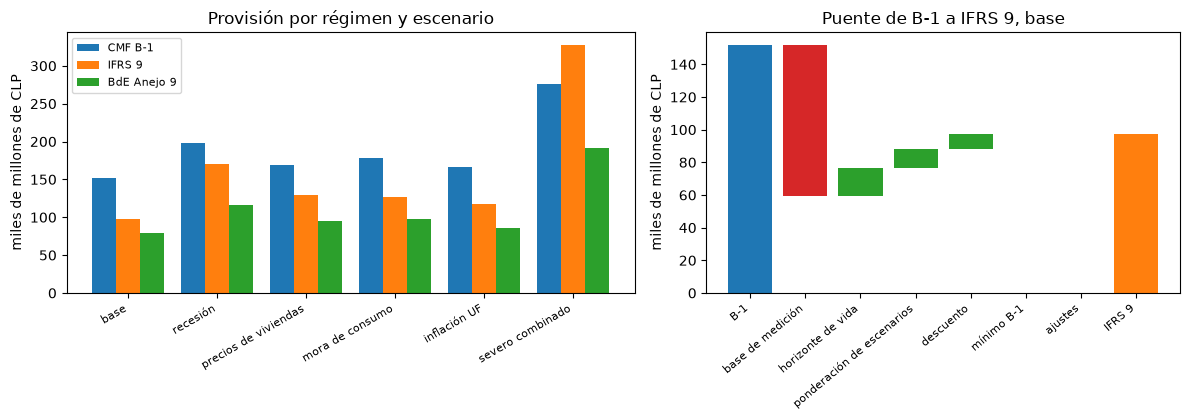

In [9]:
# Dibujar las provisiones por régimen y escenario y el puente de B-1 a IFRS 9
SCENARIO_SHORT = {"base": "base", "recession": "recesión", "house-price-fall": "precios de viviendas",
                  "consumer-arrears-shock": "mora de consumo", "uf-inflation-spike": "inflación UF", "combined-severe": "severo combinado"}
STEP_SHORT = {"measurement-basis": "base de medición", "lifetime-horizon": "horizonte de vida", "forward-looking": "ponderación de escenarios",
              "discounting": "descuento", "b1-minimum-top-up": "mínimo B-1", "ifrs9-overlays": "ajustes"}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(len(NAMES))
for k, (regime, color, label) in enumerate((("cmf-b1", "tab:blue", "CMF B-1"), ("ifrs9", "tab:orange", "IFRS 9"), ("bde-annex9", "tab:green", "BdE Anejo 9"))):
    left.bar(x + (k - 1) * 0.27, [by_regime[n][regime] / 1e9 for n in NAMES], width=0.27, color=color, label=label)
left.set_xticks(x)
left.set_xticklabels([SCENARIO_SHORT[n] for n in NAMES], rotation=30, ha="right", fontsize=8)
left.set_ylabel("miles de millones de CLP")
left.set_title("Provisión por régimen y escenario")
left.legend(fontsize=8)

level = totals["cmf_b1_provision"] / 1e9
right.bar(0, level, color="tab:blue")
labels = ["B-1"]
for i, step in enumerate(bridge["steps"], start=1):
    amount = step["amount"] / 1e9
    right.bar(i, abs(amount), bottom=level if amount >= 0 else level + amount, color="tab:green" if amount >= 0 else "tab:red")
    level += amount
    labels.append(STEP_SHORT[step["id"]])
right.bar(len(bridge["steps"]) + 1, level, color="tab:orange")
labels.append("IFRS 9")
right.set_xticks(range(len(labels)))
right.set_xticklabels(labels, rotation=40, ha="right", fontsize=8)
right.set_ylabel("miles de millones de CLP")
right.set_title("Puente de B-1 a IFRS 9, base")
fig.tight_layout()
plt.show()

## Resultados

- **Las tablas B-1 se leen como se transcribieron.** Para un hipotecario con razón préstamo a garantía (PVG) entre 40 % y 80 % y sin mora, $PI = 0{,}019158$ y $PDI = 0{,}021955$, así que $PE = 0{,}000421$ (0,0421 %); con PVG hasta 40 % es 0,000002, y en incumplimiento sobre 90 % es 0,302436. En las veinte celdas el $PE$ transcrito es igual a $PI \times PDI$ dentro de 5e-7. Un préstamo comercial al día con garantía con un PTVG de 0,8 tiene $PE = 0{,}005989$ y sin garantía 0,027938; el préstamo de consumo en cuotas del ejemplo tiene 0,015741; las categorías individuales A1, A4 y B4 tienen 0,00036, 0,0175 y 0,43875.
- **Las reglas grupales calculan como dice el compendio.** Con una exposición de 1.000, un $PE$ de 0,05 y 20 % garantizado a 0,01 la provisión es 42,0; la regla del máximo da 120 para un estándar de 100 y un interno de 120, el interno de 120 cuando no es objetado, y 100 sin método interno. Banco Andino no tiene método interno, así que la provisión estándar es la aplicada en los cinco segmentos grupales, igual a los valores versionados (la razón versionada está registrada solo en inglés).
- **El mínimo y las provisiones adicionales son separados.** El mínimo de 0,50 % de la cartera normal evaluada individualmente es 8.457,4 millones de CLP, igual al monto versionado, y no es vinculante; con una provisión de 5.000 millones sería vinculante con un complemento de 3.457,4. Las provisiones adicionales de 3.000 millones están dentro del rango del directorio de 0 a 15.000, y 20.000 se rechaza. El total B-1 contabilizado, 155.000,6 millones, es el total comparable, 152.000,6, más las provisiones adicionales.
- **El Anejo 9 se lee como un coeficiente sobre el monto no cubierto.** El riesgo normal de vivienda es 0,007 y la vigilancia especial 0,18; el crédito al consumo 0,018; la construcción 0,019. Para el riesgo dudoso de vivienda el coeficiente es 0,45 hasta 183 días, 0,50 desde 184, 0,65 a los 365 y 1,0 a los 700; una cuenta de 1.000 con garantías de 300 en vivienda normal tiene una cobertura de 4,9. La correspondencia de categorías a etapas del motor coincide con la versionada en las tres categorías, y las tasas de cobertura recalculadas (0,3723 %, 5,7243 % y 26,5210 %) son iguales a las versionadas. Una cuenta dudosa sin días de mora se rechaza: el motor no inventa un coeficiente.
- **Una cartera, tres totales.** La suma de los segmentos más las líneas sin asignar es igual a los totales versionados: 152.000,6 millones bajo B-1, 97.592,0 bajo IFRS 9 (incluidos 324,1 de ajustes como líneas sin asignar) y 79.618,5 bajo el Anejo 9. IFRS 9 es 64,21 % de B-1 y el Anejo 9 es 52,38 %. Por segmento el orden cambia: los hipotecarios de PVG bajo llevan 0,11 % bajo B-1, 0,64 % bajo IFRS 9 y nada bajo el Anejo 9, mientras que los préstamos de consumo en cuotas llevan 8,01 %, 2,59 % y 4,41 %.
- **El puente es una lista de decisiones.** Desde 152,001 miles de millones de CLP bajo B-1 la base de medición resta 92,548, la pérdida de vida completa de la Etapa 2 suma 17,134, la ponderación por probabilidad 11,625, el descuento a la TIE 9,056, el complemento del mínimo B-1 0 y los ajustes 0,324, lo que da 97,592, el total IFRS 9. La brecha de $-54{,}409$ es en su mayor parte el primer paso: la PD, la pérdida dado el incumplimiento y las recuperaciones del banco frente a las matrices B-1.
- **El orden de los regímenes no sobrevive a toda tensión.** IFRS 9 sobre B-1 es 0,642 en el base y 0,860, 0,763, 0,707 y 0,703 en la recesión, la caída de precios de viviendas, el choque de mora de consumo y el alza de la inflación en UF. En el caso severo combinado es 1,189: IFRS 9 llega a 327,8 miles de millones frente a 275,8 de B-1. Del base a ese caso B-1 sube 123,8 miles de millones, IFRS 9 sube 230,2 y el Anejo 9 sube 112,0. El cambio versionado es igual a la diferencia de los totales.

Lo que este cuaderno no muestra: Banco Andino es sintético, sus choques, ajustes y provisiones adicionales son supuestos del caso, y la columna IFRS 9 es una medida de comparación que los bancos chilenos no contabilizan sobre los préstamos. La propuesta de reforma de la CMF de agosto de 2026 (escala de PI recalibrada, métodos internos) no está vigente y no se implementa; los números de punto del Anejo 9 son los de la Circular 6/2021. El cuaderno no dice nada sobre si algún banco real se provisionaría así.

## Resumen

- Los bancos chilenos contabilizan provisiones B-1 sobre los préstamos, no el deterioro de IFRS 9; B-1 es una tabla de celdas $PE = PI \times PDI$ con una regla del máximo, un mínimo y una línea separada de provisiones adicionales, y el motor guarda cada tabla transcrita celda por celda.
- El Anejo 9 del Banco de España es un coeficiente sobre el monto no cubierto, por segmento y categoría, con una correspondencia a las etapas de IFRS 9.
- Sobre un banco sintético los tres regímenes dan tres totales; la brecha entre B-1 e IFRS 9 es un puente de decisiones nombradas, dominado por la base de medición.
- El orden de los regímenes depende de la economía: IFRS 9 está muy bajo B-1 en el base y sobre él en el caso severo combinado.
- Banco Andino es sintético y sus choques son supuestos; la comparación enseña la mecánica, no valora ningún banco real.

**Qué probar a continuación.** Cambia el `pvg` y el `dpd` de la búsqueda hipotecaria para leer otras celdas; da a `b1_group_max_rule` un monto interno sobre el estándar para un segmento grupal y recalcula el total B-1. Después sigue con el cuaderno 07, que abre los modelos de PD de vida completa que alimentan la columna IFRS 9.

## Referencias

- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Capítulos A-2 (N 5) y B-1 (N 2, N 3, N 4 y N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 4/2017, norma 29 y Anejo 9 (BOE-A-2017-14334). https://www.boe.es/buscar/act.php?id=BOE-A-2017-14334
- Banco de España, Circular 6/2021 de 22 de diciembre (BOE-A-2021-21666): las tablas de los puntos 140, 144 y 172, aplicables desde el 30 de junio de 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm